In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

In [3]:
x, labels = next(iter(train_loader))

print(x.shape)
print(labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])


In [4]:
class VAEEncoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.shared = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU()
        )

        self.mu = nn.Linear(32, latent_dim)
        self.log_var = nn.Linear(32, latent_dim)

    def forward(self, x):
        h = self.shared(x)

        mu = self.mu(h)
        log_var = self.log_var(h)

        return mu, log_var

In [5]:
encoder = VAEEncoder(latent_dim=2)

x, labels = next(iter(train_loader))
x = x.view(x.size(0), -1)

mu, log_var = encoder(x)

print(mu.shape)
print(log_var.shape)

torch.Size([64, 2])
torch.Size([64, 2])


In [6]:
std = torch.exp(0.5 * log_var)
eps = torch.randn_like(std)
z = mu + eps * std

print("mu:", mu.shape)
print("std:", std.shape)
print("eps:", eps.shape)
print("z:", z.shape)

mu: torch.Size([64, 2])
std: torch.Size([64, 2])
eps: torch.Size([64, 2])
z: torch.Size([64, 2])


In [7]:
from torch import sigmoid


class VAEDecoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),

            nn.Linear(32, 128),
            nn.ReLU(),

            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.decoder(z)

In [8]:
decoder = VAEDecoder(latent_dim=2)

x_hat = decoder(z)

print(x_hat.shape)

torch.Size([64, 784])


In [9]:
from turtle import forward


class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = VAEEncoder(latent_dim)
        self.decoder = VAEDecoder(latent_dim)

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        z = mu + eps * std
        return z

    def forward(self, x):
        mu, log_var = self.encoder(x)
        z = self.reparameterize(mu, log_var)
        x_hat = self.decoder(z)

        return x_hat, mu, log_var

In [10]:
model = VAE(latent_dim=2)

x, labels = next(iter(train_loader))
x = x.view(x.size(0), -1)

x_hat, mu, log_var = model(x)

print("Reconstructed:", x_hat.shape)
print("Mu:", mu.shape)
print("Log variance:", log_var.shape)

Reconstructed: torch.Size([64, 784])
Mu: torch.Size([64, 2])
Log variance: torch.Size([64, 2])


In [11]:
def vae_loss(x_hat, x, mu, log_var):
    reconstruction_loss = nn.functional.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + log_var - mu.pow(2) - log_var.exp()
    )

    total_loss = reconstruction_loss + kl_loss

    return total_loss, reconstruction_loss, kl_loss

In [12]:
total, recon, kl = vae_loss(x_hat, x, mu, log_var)

print("Total loss:", total.item())
print("Reconstruction loss:", recon.item())
print("KL loss:", kl.item())

Total loss: 34914.0390625
Reconstruction loss: 34913.7109375
KL loss: 0.3299175798892975


In [13]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [14]:
epochs = 10

for epoch in range(epochs):
    model.train()

    total_loss = 0
    total_recon = 0
    total_kl = 0

    for x, _ in train_loader:
        x = x.view(x.size(0), -1)

        x_hat, mu, log_var = model(x)

        loss, recon, kl = vae_loss(
            x_hat, x, mu, log_var
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_recon += recon.item()
        total_kl += kl.item()

    avg_loss = total_loss / len(train_loader.dataset)
    avg_recon = total_recon / len(train_loader.dataset)
    avg_kl = total_kl / len(train_loader.dataset)

    print(
        f"Epoch {epoch + 1}:"
        f"Total {avg_loss:.4f},"
        f"Recon {avg_recon:.4f},"
        f"KL {avg_kl:.4f}"
    )

c:\Users\boost\anaconda3\Lib\site-packages\torch\autograd\graph.py:882: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 11060). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10\cuda\CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 1:Total 192.1837,Recon 188.2055,KL 3.9782
Epoch 2:Total 167.4320,Recon 162.6740,KL 4.7580
Epoch 3:Total 162.8324,Recon 157.7981,KL 5.0343
Epoch 4:Total 159.0824,Recon 153.7532,KL 5.3293
Epoch 5:Total 156.6111,Recon 151.0965,KL 5.5145
Epoch 6:Total 154.7810,Recon 149.1496,KL 5.6314
Epoch 7:Total 153.3520,Recon 147.6179,KL 5.7342
Epoch 8:Total 152.1133,Recon 146.2651,KL 5.8483
Epoch 9:Total 150.9698,Recon 145.0583,KL 5.9115
Epoch 10:Total 150.1049,Recon 144.0987,KL 6.0062


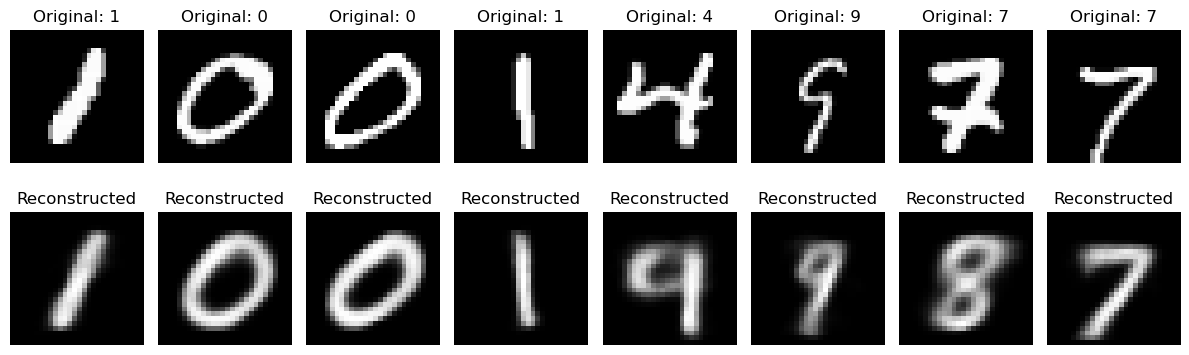

In [15]:
model.eval()

x, labels = next(iter(train_loader))
x_flat = x.view(x.size(0), -1)

with torch.no_grad():
    x_hat, mu, log_var = model(x_flat)

fig, axes = plt.subplots(2, 8, figsize=(12, 4))

for i in range(8):
    axes[0, i].imshow(x[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[0, i].set_title(f"Original: {labels[i].item()}")

    axes[1, i].imshow(
        x_hat[i].view(28, 28).cpu().numpy(),
        cmap="gray"
    )
    axes[1, i].axis("off")
    axes[1, i].set_title("Reconstructed")

plt.tight_layout()
plt.show()

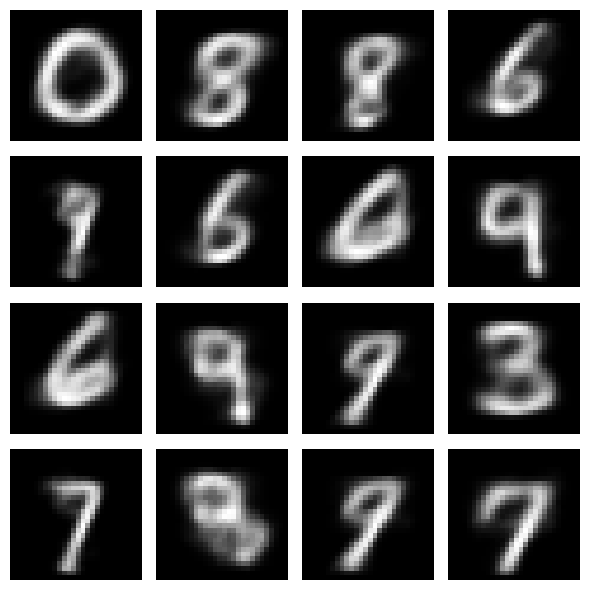

In [16]:
model.eval()

with torch.no_grad():
    z = torch.randn(16, 2)
    generated = model.decoder(z)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i].view(28, 28).numpy(), cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()

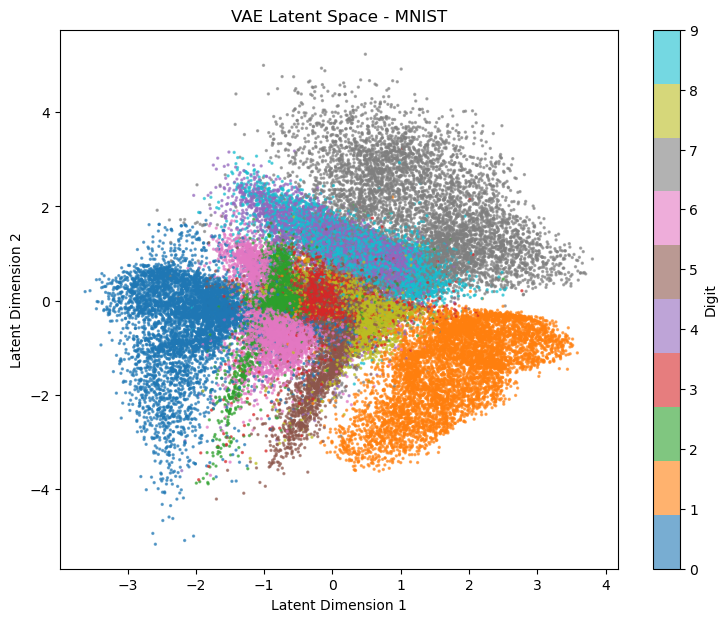

In [19]:
from torch import scatter


model.eval()

all_mu = []
all_labels = []

with torch.no_grad():
    for x, labels in train_loader:
        x = x.view(x.size(0), -1)

        mu, log_var = model.encoder(x)

        all_mu.append(mu)
        all_labels.append(labels)

all_mu = torch.cat(all_mu).numpy()
all_labels = torch.cat(all_labels).numpy()

plt.figure(figsize=(9, 7))

scatter = plt.scatter(
    all_mu[:, 0],
    all_mu[:, 1],
    c=all_labels,
    cmap="tab10",
    s=2,
    alpha=0.6
)

plt.colorbar(scatter, ticks=range(10), label="Digit")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("VAE Latent Space - MNIST")
plt.show()